# 02 — Models, tuning, ensemble, evaluation and explainability

Training is run by `python -m src.train` (≈1–2 h on a laptop) and explanations by `python -m src.explain`.
This notebook loads their saved outputs, so it runs in seconds and every number here is reproducible.

**Evaluation protocol**
* 20% of households (592) are held out as the **test set** and used once, at the end.
* Model comparison and tuning use **5-fold cross-validation grouped by household** on the other 80% (2,333
  households): no household's days are ever in both the fitting and the scoring folds.
* The main metric is **household accuracy**: a household-period is classified by averaging its day probabilities
  (households that installed solar part-way contribute a *before* and an *after* period).
* Also reported: F1, precision, recall, AUC, day-level accuracy, and the majority-class baseline.

In [1]:
import sys, json
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
sns.set_theme(style='whitegrid')
R, FIG, EX = '../reports/', '../reports/figures/', '../reports/explain/'
comp = pd.read_csv(R + 'model_comparison.csv')
meta = json.load(open('../models/metadata.json'))
cols = ['model', 'stage', 'cv_hh_accuracy', 'cv_hh_f1', 'cv_hh_auc', 'test_hh_accuracy', 'test_hh_errors',
        'test_hh_n', 'test_hh_f1', 'test_hh_precision', 'test_hh_recall', 'test_hh_auc', 'test_day_accuracy', 'seconds']
comp[cols].round(4)

,model,stage,cv_hh_accuracy,cv_hh_f1,cv_hh_auc,test_hh_accuracy,test_hh_errors,test_hh_n,test_hh_f1,test_hh_precision,test_hh_recall,test_hh_auc,test_day_accuracy,seconds
0,Dummy (majority),default,0.8375,0.0000,0.5000,0.8306,103,608,0.0000,0.0000,0.0000,0.5000,0.8539,0.6
1,Logistic Regression,default,0.9727,0.9125,0.9921,0.9770,14,608,0.9293,0.9684,0.8932,0.9960,0.9569,9.2
2,KNN (k=25),default,0.9794,0.9337,0.9971,0.9836,10,608,0.9490,1.0000,0.9029,0.9972,0.9615,32.5
3,Decision Tree,default,0.9895,0.9670,0.9981,0.9868,8,608,0.9600,0.9897,0.9320,0.9983,0.9773,79.1
4,Random Forest,default,0.9882,0.9629,0.9990,0.9885,7,608,0.9648,1.0000,0.9320,0.9989,0.9837,372.3
5,Extra Trees,default,0.9861,0.9563,0.9983,0.9885,7,608,0.9648,1.0000,0.9320,0.9986,0.9818,41.7
6,HistGradientBoosting,default,0.9895,0.9669,0.9983,0.9868,8,608,0.9600,0.9897,0.9320,0.9983,0.9831,29.0
7,XGBoost,default,0.9903,0.9697,0.9984,0.9885,7,608,0.9652,0.9898,0.9417,0.9987,0.9841,56.9
8,LightGBM,default,0.9882,0.9629,0.9985,0.9885,7,608,0.9652,0.9898,0.9417,0.9987,0.9840,54.7
9,CatBoost,default,0.9899,0.9683,0.9986,0.9885,7,608,0.9652,0.9898,0.9417,0.9985,0.9840,98.2


## 1. Comparing model families (default settings)

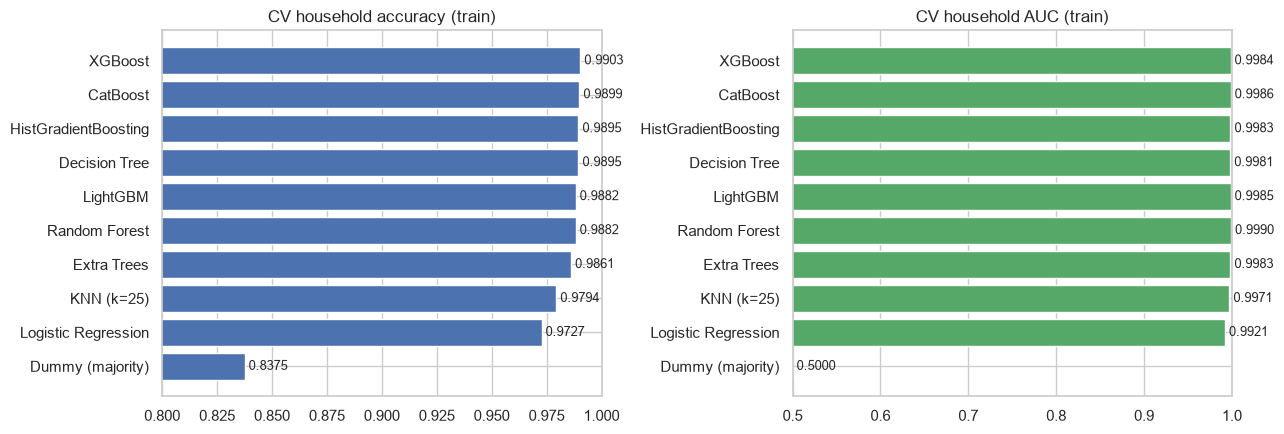

In [2]:
d = comp[comp.stage == 'default'].sort_values('cv_hh_accuracy')
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].barh(d.model, d.cv_hh_accuracy, color='#4C72B0'); ax[0].set(xlim=(0.8, 1.0), title='CV household accuracy (train)')
ax[1].barh(d.model, d.cv_hh_auc, color='#55A868'); ax[1].set(xlim=(0.5, 1.0), title='CV household AUC (train)')
for a, col in zip(ax, ['cv_hh_accuracy', 'cv_hh_auc']):
    for i, v in enumerate(d[col]): a.text(v, i, f' {v:.4f}', va='center', fontsize=9)
plt.tight_layout(); plt.savefig(FIG + 'model_comparison_default.png', dpi=120); plt.show()

* The **majority baseline** (always "no solar") already scores ~84% — accuracy alone flatters weak models, which is
  why F1 and AUC are reported too.
* **Logistic regression** is strong (the solar "bowl" is close to linearly separable once expressed as ratios),
  but tree ensembles capture interactions — e.g. *low midday import* means solar only if night/evening import is
  normal (otherwise the house is simply empty).
* **KNN** is competitive but slow to predict and sensitive to scaling; a single **decision tree** overfits.
* **Gradient boosting** (XGBoost, LightGBM, CatBoost, HistGB) and **bagging** (Random Forest, Extra Trees) are the
  strongest families, so they are tuned and combined.

## 2. Hyperparameter tuning (Optuna, grouped CV)

In [3]:
params = json.load(open(R + 'best_params.json'))
for k, v in params.items(): print(k, {p: (round(x, 4) if isinstance(x, float) else x) for p, x in v.items()})
dt = comp[comp.model.str.replace(' (tuned)', '', regex=False).isin(params)].copy()
dt['family'] = dt.model.str.replace(' (tuned)', '', regex=False)
pv = dt.pivot_table(index='family', columns='stage', values=['cv_hh_accuracy', 'cv_day_logloss'])
pv.round(4)

LightGBM {'n_estimators': 300, 'learning_rate': 0.0162, 'num_leaves': 47, 'min_child_samples': 27, 'subsample': 0.8844, 'colsample_bytree': 0.7362, 'reg_lambda': 1.421}
XGBoost {'n_estimators': 400, 'learning_rate': 0.0114, 'max_depth': 6, 'min_child_weight': 4.3999, 'subsample': 0.9219, 'colsample_bytree': 0.6076, 'reg_lambda': 0.7215}
CatBoost {'iterations': 400, 'learning_rate': 0.0286, 'depth': 4, 'l2_leaf_reg': 13.3943}
Extra Trees {'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 0.5283}


cv_day_logloss         cv_hh_accuracy        
stage              default   tuned        default   tuned
family                                                   
CatBoost            0.0606  0.0686         0.9899  0.9870
Extra Trees         0.0759  0.0704         0.9861  0.9887
LightGBM            0.0620  0.0641         0.9882  0.9895
XGBoost             0.0616  0.0650         0.9903  0.9882

Tuning searched learning rate, tree size/depth, regularisation and sampling with Optuna's TPE sampler, minimising
**day-level log-loss** on household-grouped folds (a smooth objective; accuracy is too coarse to tune on). To keep
run time reasonable on a laptop, the search used a random **25% of the training households** (3 folds); every
candidate was then re-scored on the full 5-fold CV above.

**Honest reading of the result: tuning did not improve the boosting models.** For LightGBM, XGBoost and CatBoost the
tuned settings have a slightly *higher* full-CV log-loss than the defaults; only Extra Trees improved. The search
picked low learning rates with few trees, which fitted the smaller tuning subsample well but under-fit at full scale.
Two lessons:
* the libraries' defaults were already close to optimal for this signal-rich problem, and
* tuning on a subsample can choose capacity that does not transfer to the full data — a better (but ~4× slower)
  protocol tunes on all training households, or tunes the number of trees with early stopping.

The household-accuracy differences in the table (0.9870–0.9903) correspond to only about 3–8 households out of
2,382 — within the noise of a single CV run.

## 3. The ensemble

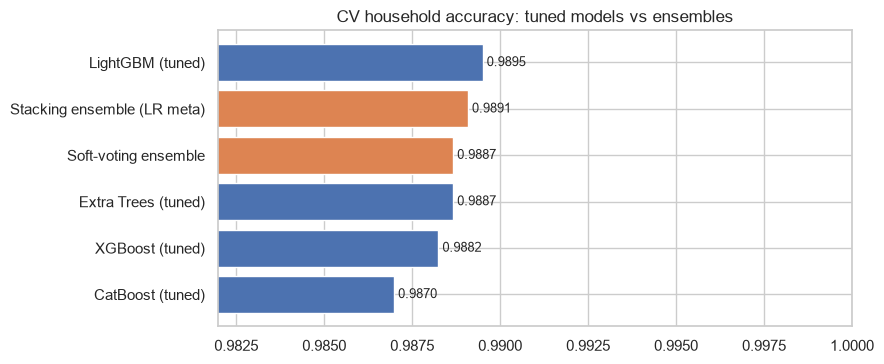

Stacking meta-learner (logistic regression) weights:
extra_trees    6.239
lightgbm       1.368
xgboost        1.024
catboost       0.907
Name: 0, dtype: float64


In [4]:
e = comp[comp.stage.isin(['tuned', 'ensemble'])].sort_values('cv_hh_accuracy')
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(e.model, e.cv_hh_accuracy, color=['#DD8452' if 'ensemble' in m else '#4C72B0' for m in e.model])
lo = e.cv_hh_accuracy.min() - 0.005
ax.set(xlim=(lo, 1.0), title='CV household accuracy: tuned models vs ensembles')
for i, v in enumerate(e.cv_hh_accuracy): ax.text(v, i, f' {v:.4f}', va='center', fontsize=9)
plt.tight_layout(); plt.savefig(FIG + 'model_comparison_ensemble.png', dpi=120); plt.show()
w = pd.read_csv(EX + 'stacking_weights.csv', index_col=0).iloc[:, 0]
print('Stacking meta-learner (logistic regression) weights:'); print(w.round(3))

In cross-validation the ensembles are **on par** with the best single models (all within ~3 households), so CV
alone does not prove the ensemble is better. Where it helps is **stability**: it averages learners that make different
mistakes, and on the untouched test households it made the fewest errors (6 at the default 0.5 threshold, 5 at the
threshold chosen on training data, vs 7 for every single model).

**Stacking**: four tuned base learners (LightGBM, XGBoost, CatBoost, Extra Trees) each produce out-of-fold day
probabilities on household-grouped folds; a logistic regression learns how to weight them. The base learners make
different kinds of mistakes (boosting vs bagging, different tree growth), so combining them reduces variance.
Because the meta-features are out-of-fold *and grouped by household*, the meta-learner never sees a prediction made
on a household that the base model was trained on.

## 4. Final result on the held-out test households

In [5]:
t = meta['test_households']; v = meta['cv_train_households']
pd.DataFrame({'CV (train households)': v, 'Held-out test': t}).loc[
    ['hh_accuracy', 'hh_errors', 'hh_n', 'hh_f1', 'hh_precision', 'hh_recall', 'hh_auc', 'day_accuracy', 'day_auc']].round(5)

,CV (train households),Held-out test
hh_accuracy,0.99118,0.99178
hh_errors,21.00000,5.00000
hh_n,2382.00000,608.00000
hh_f1,0.97248,0.97512
hh_precision,0.98670,1.00000
hh_recall,0.95866,0.95146
hh_auc,0.99843,0.99727
day_accuracy,0.97896,0.98350
day_auc,0.99018,0.99404


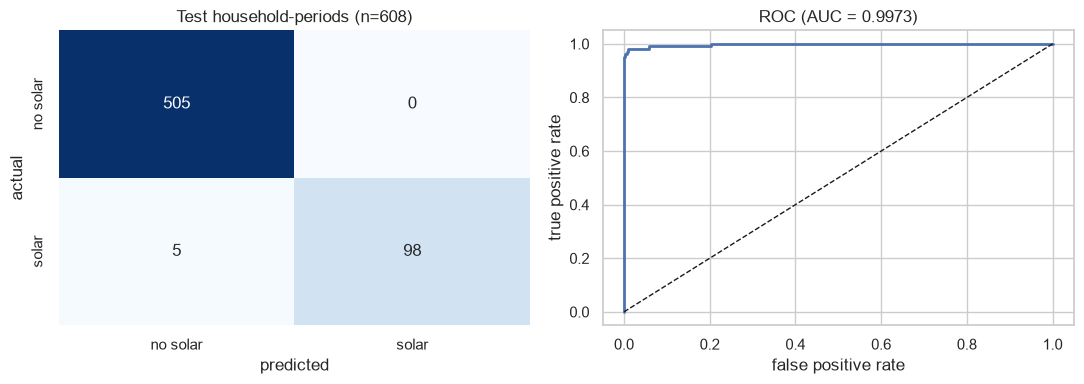

In [6]:
from sklearn.metrics import confusion_matrix, roc_curve
hp = pd.read_csv(R + 'test_household_predictions.csv')
cm = confusion_matrix(hp.solar_installed, hp.pred)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0],
            xticklabels=['no solar', 'solar'], yticklabels=['no solar', 'solar'])
ax[0].set(xlabel='predicted', ylabel='actual', title=f"Test household-periods (n={len(hp)})")
fpr, tpr, _ = roc_curve(hp.solar_installed, hp.p_solar)
ax[1].plot(fpr, tpr, lw=2); ax[1].plot([0, 1], [0, 1], 'k--', lw=1)
ax[1].set(xlabel='false positive rate', ylabel='true positive rate', title=f"ROC (AUC = {t['hh_auc']:.4f})")
plt.tight_layout(); plt.savefig(FIG + 'test_confusion_roc.png', dpi=120); plt.show()

## 5. Error analysis

Every misclassified test household-period, with the information needed to understand it. The model and threshold
were frozen before this analysis; nothing below was used to change them.

In [7]:
err = hp[hp.pred != hp.solar_installed].copy()
err['type'] = np.where(err.solar_installed == 1, 'missed solar', 'false alarm')
err['segment'] = np.where(err.unit.str.endswith(':0') & (err.export_kwh > 1), 'before installation', 'whole period')
err.sort_values('p_solar')[['unit', 'type', 'segment', 'p_solar', 'n_days', 'export_kwh', 'first_export_day']].round(3)

,unit,type,segment,p_solar,n_days,export_kwh,first_export_day
379,ID4448:1,missed solar,whole period,0.013,3,21.404,2024-05-31
582,ID5472:1,missed solar,whole period,0.037,88,93.075,2024-06-26
8,ID0183:1,missed solar,whole period,0.148,182,3072.525,2024-04-13
31,ID0485:1,missed solar,whole period,0.195,21,463.295,2023-12-13
600,ID5543:1,missed solar,whole period,0.417,25,482.273,2024-09-15


In [8]:
bins = [0, 3, 7, 14, 30, 10_000]
hp['days_available'] = pd.cut(hp.n_days, bins, labels=['1-3', '4-7', '8-14', '15-30', '>30'])
acc = hp.assign(ok=hp.pred == hp.solar_installed).groupby('days_available', observed=True).agg(
    units=('ok', 'size'), errors=('ok', lambda s: int((~s).sum())), accuracy=('ok', 'mean'))
acc.round(4)

,units,errors,accuracy
days_available,,,
1-3,10,1,0.9000
4-7,1,0,1.0000
8-14,3,0,1.0000
15-30,12,2,0.8333
>30,582,2,0.9966


How accuracy depends on **how many days of data** a household has: one day can be ambiguous (a cloudy day, a
house left empty), while averaging over weeks removes that noise. This is a property of the problem, not a tuning
choice — it tells a utility how long to observe a meter before trusting the flag.

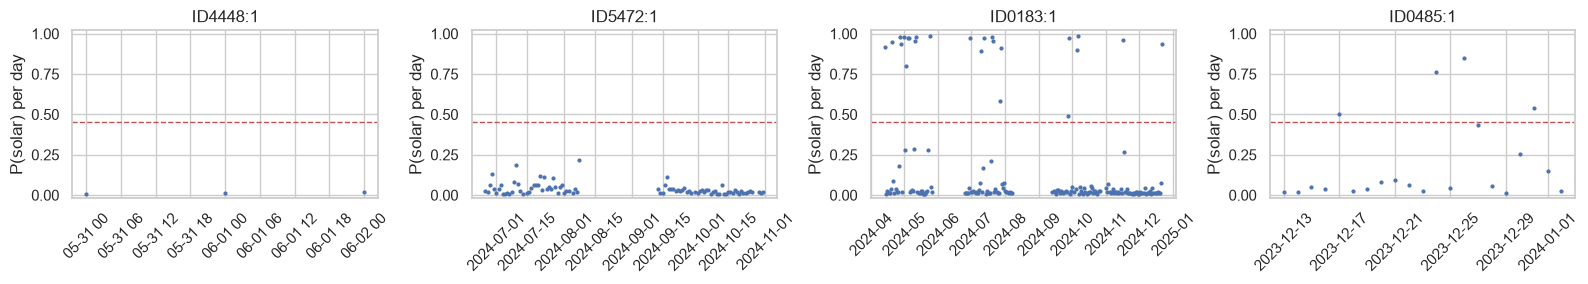

In [9]:
dp = pd.read_parquet(R + 'test_day_predictions.parquet')
sample_err = err.sort_values('p_solar').head(4).unit.tolist()
fig, axes = plt.subplots(1, len(sample_err), figsize=(4 * len(sample_err), 3), squeeze=False)
for ax, u in zip(axes[0], sample_err):
    s = dp[dp.unit == u].sort_values('day')
    ax.plot(s.day, s.p, '.', ms=4); ax.axhline(meta['threshold'], color='r', ls='--', lw=1)
    ax.set(title=u, ylim=(-.02, 1.02), ylabel='P(solar) per day'); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.savefig(FIG + 'error_examples.png', dpi=120); plt.show()

## 6. Explainability — SHAP

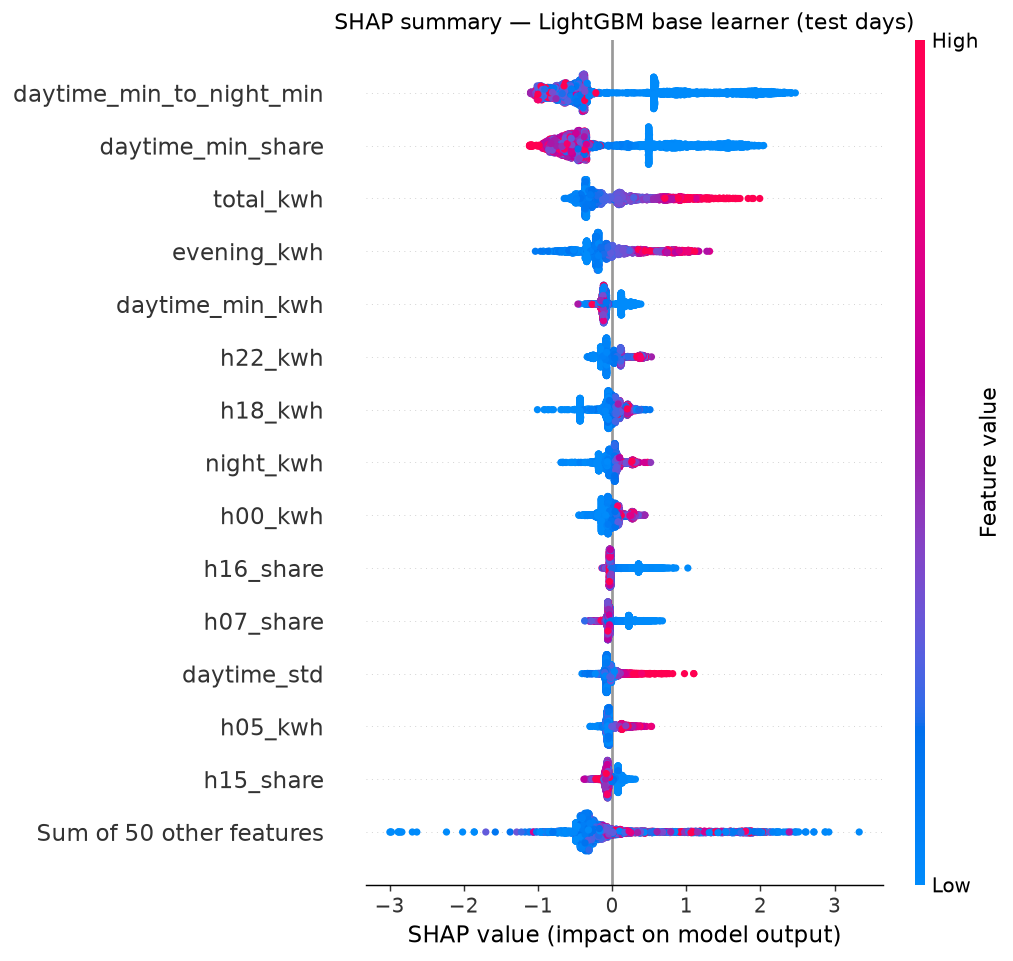

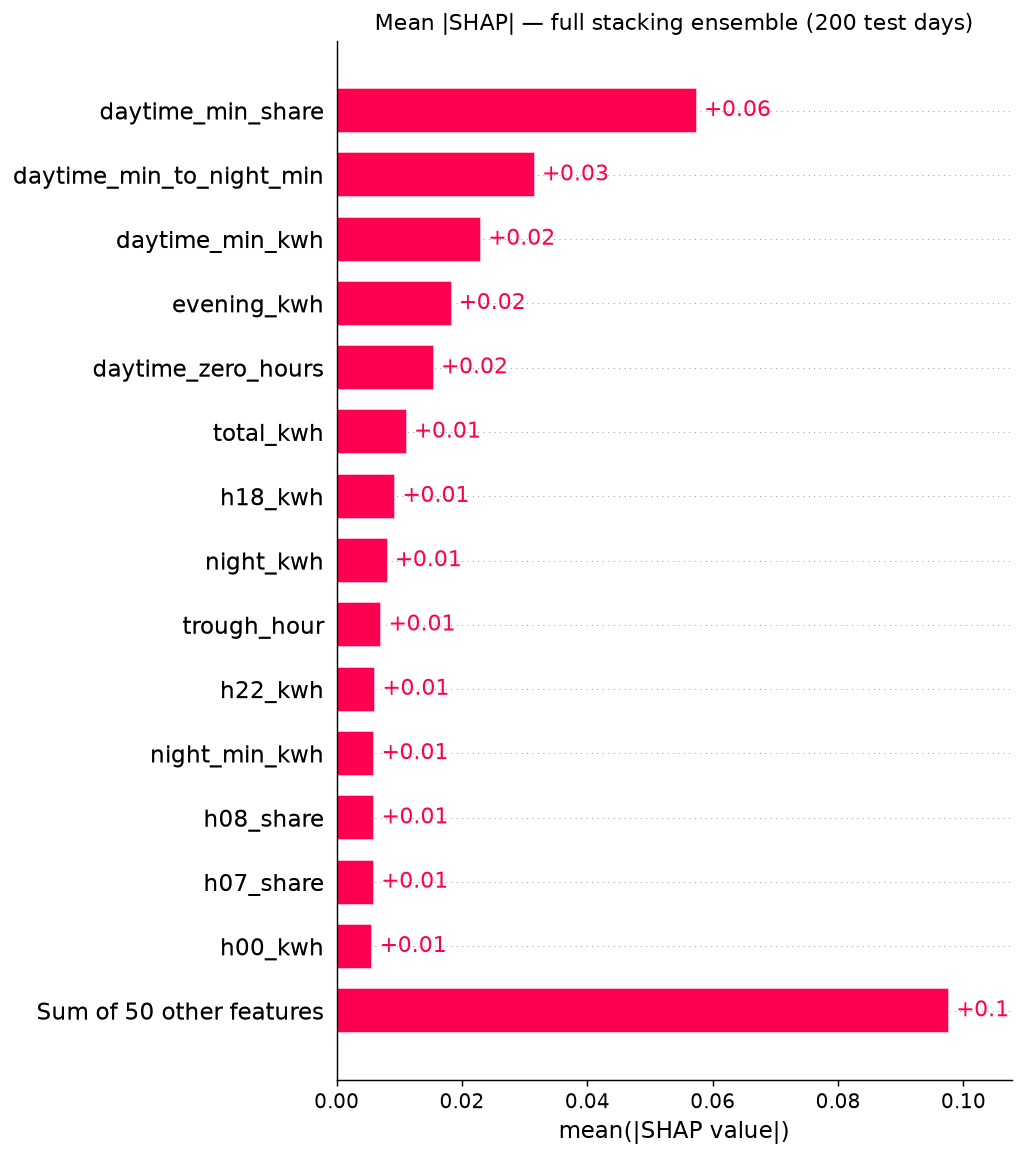

,LightGBM rank,Ensemble rank
daytime_min_share,2,1
daytime_min_to_night_min,1,2
daytime_min_kwh,5,3
evening_kwh,4,4
daytime_zero_hours,40,5
total_kwh,3,6
h18_kwh,7,7
night_kwh,8,8
trough_hour,18,9
h22_kwh,6,10


In [10]:
display(Image(EX + 'shap_beeswarm.png', width=750))
display(Image(EX + 'shap_bar_ensemble.png', width=650))
imp_b = pd.read_csv(EX + 'shap_importance_lightgbm.csv', index_col=0).iloc[:, 0]
imp_e = pd.read_csv(EX + 'shap_importance_ensemble.csv', index_col=0).iloc[:, 0]
pd.DataFrame({'LightGBM rank': imp_b.rank(ascending=False).astype(int), 'Ensemble rank': imp_e.rank(ascending=False).astype(int)}
             ).sort_values('Ensemble rank').head(12)

* **Global (beeswarm)**: the two dominant features describe *how low daytime import gets relative to the rest of the
  day* (`daytime_min_to_night_min`, `daytime_min_share`). Low values (blue) push strongly towards solar — exactly the
  physical mechanism: on a sunny day the panels cover the whole load and the meter imports nothing. `total_kwh` and
  `evening_kwh` come next: solar homes in this data are larger consumers, so high evening use is weak extra evidence.
* **Consistency check**: SHAP on the full stacking ensemble (model-agnostic permutation SHAP) ranks the same
  features at the top as tree SHAP on the base learner, so the explanation of the base learner is representative.
* **No suspicious features**: no export, meter type, ID or calendar feature appears — a SHAP ranking dominated by
  one non-physical feature would have signalled leakage.

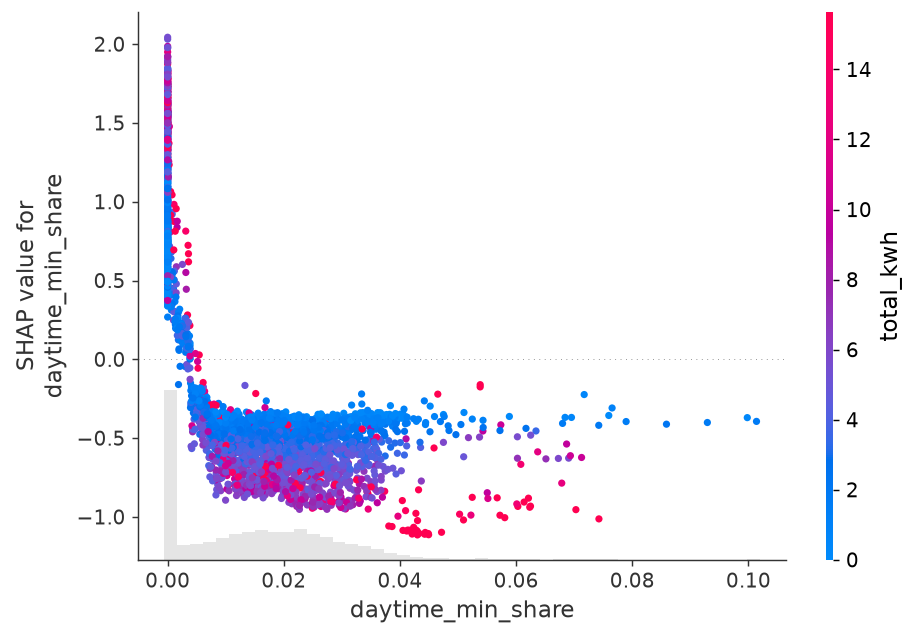

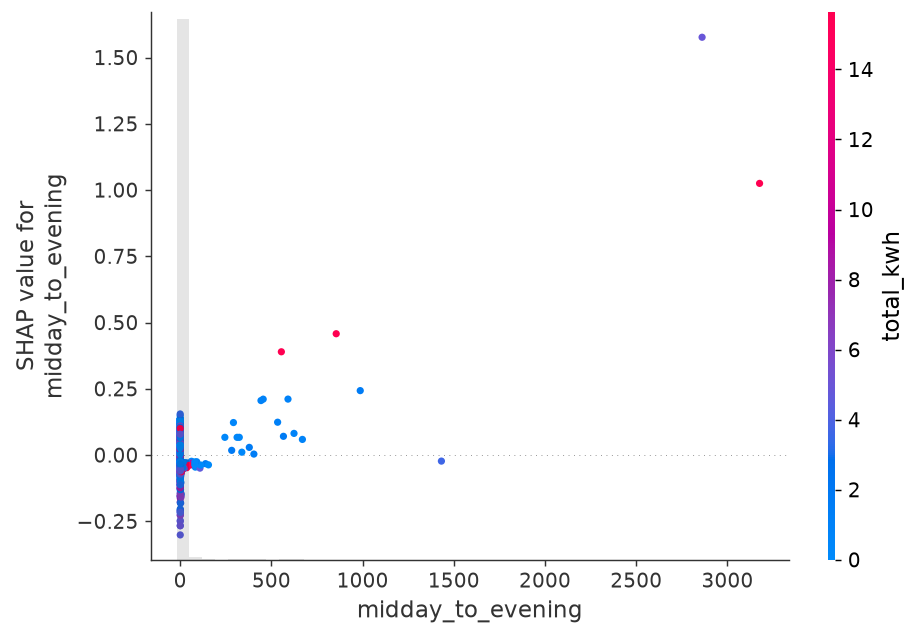

In [11]:
for f in ['shap_dependence_daytime_min_share.png', 'shap_dependence_midday_to_evening.png']:
    display(Image(EX + f, width=560))

Dependence plots show the *shape* of each effect and its interaction with total consumption (colour):
the same low midday share is stronger evidence of solar in a high-consumption home than in a near-empty one.

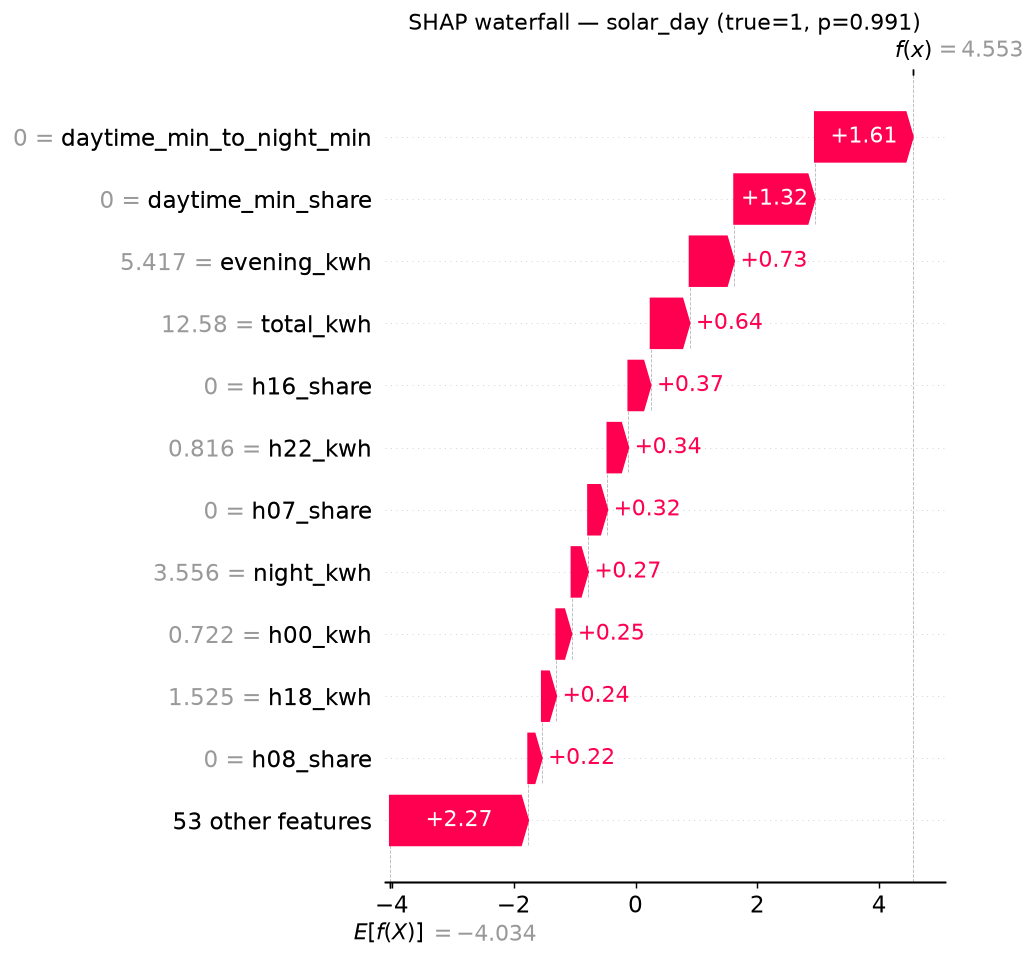

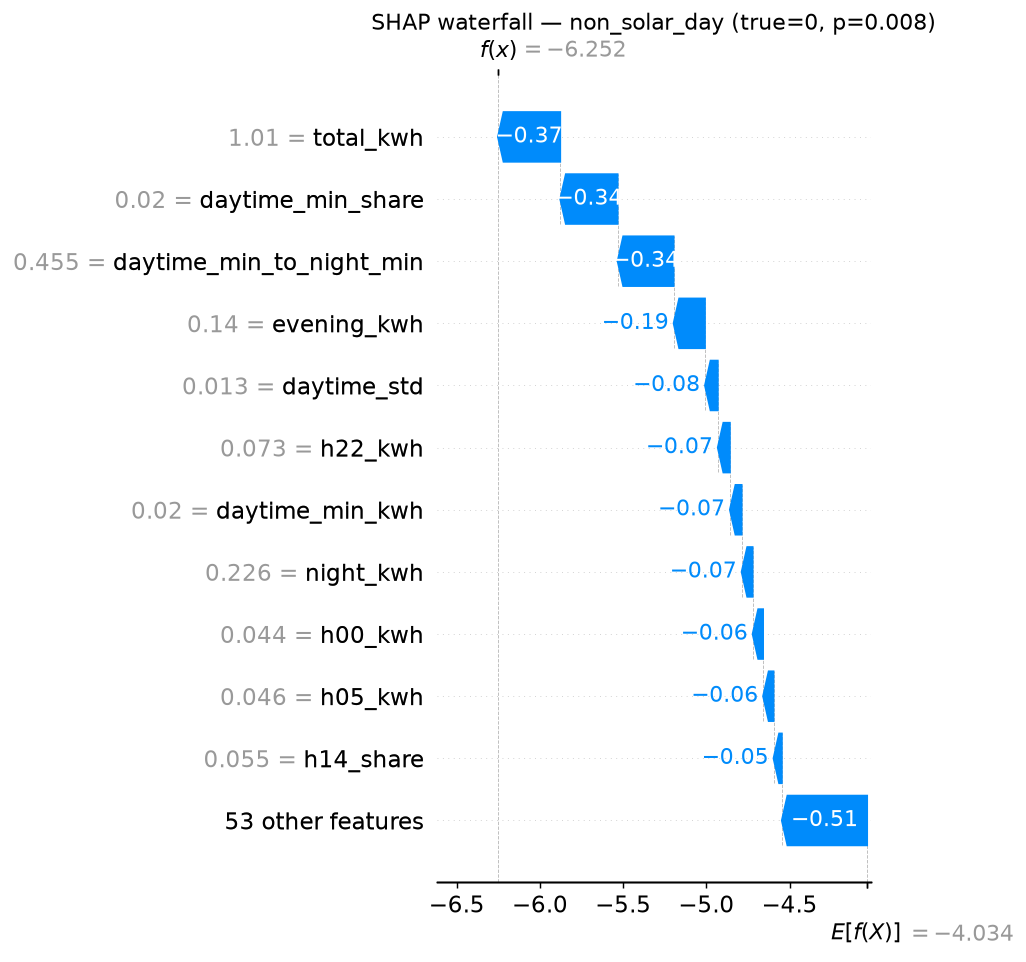

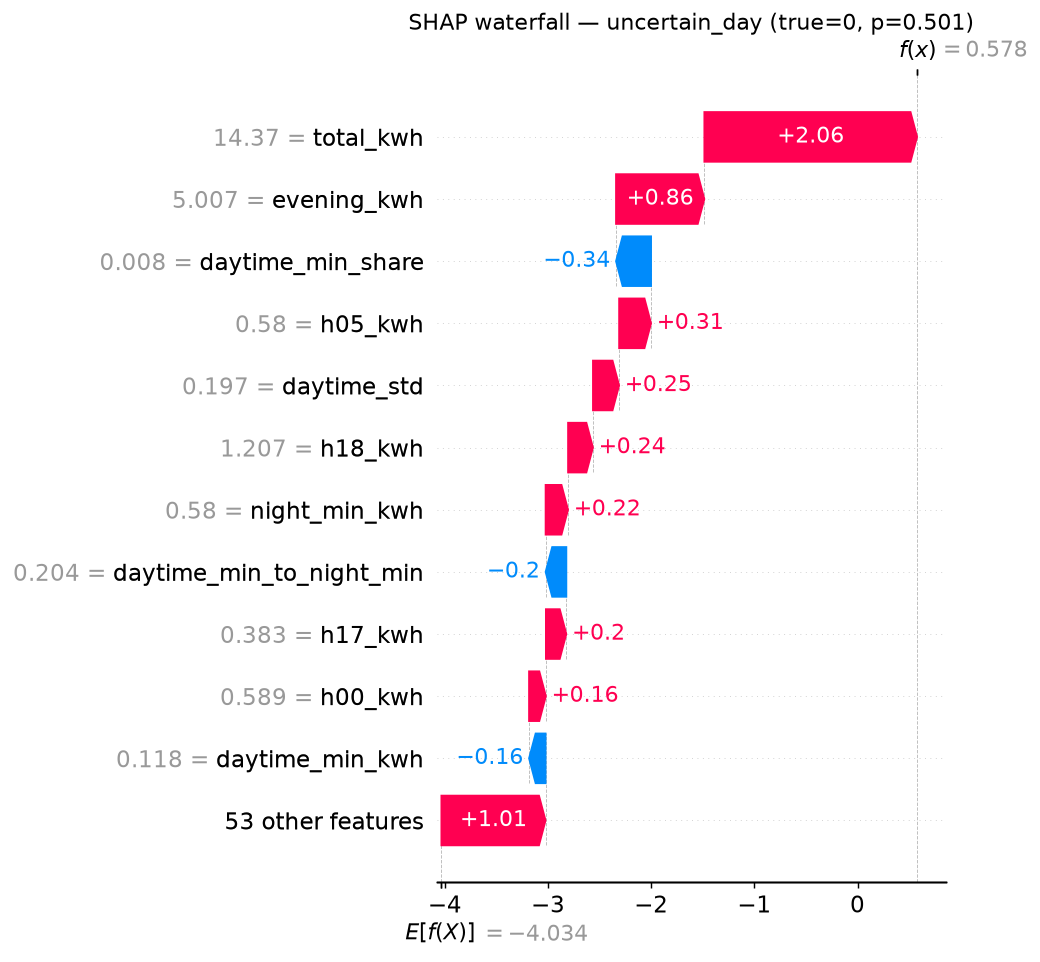

In [12]:
for case in ['solar_day', 'non_solar_day', 'uncertain_day']:
    display(Image(EX + f'shap_waterfall_{case}.png', width=620))

## 7. Explainability — LIME

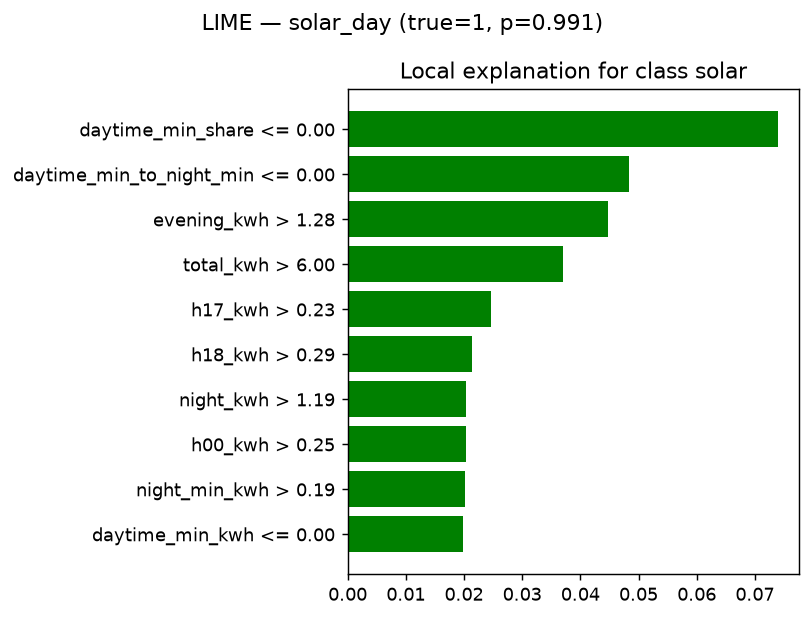

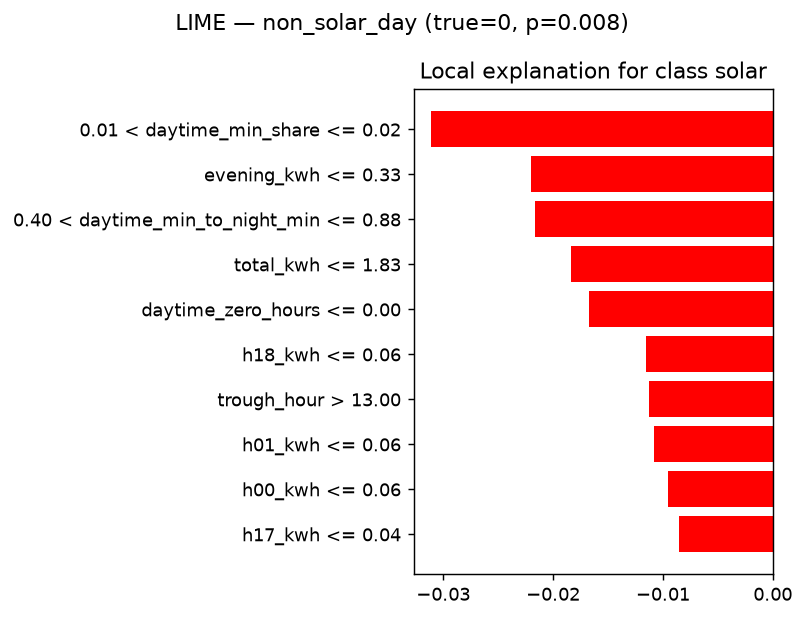

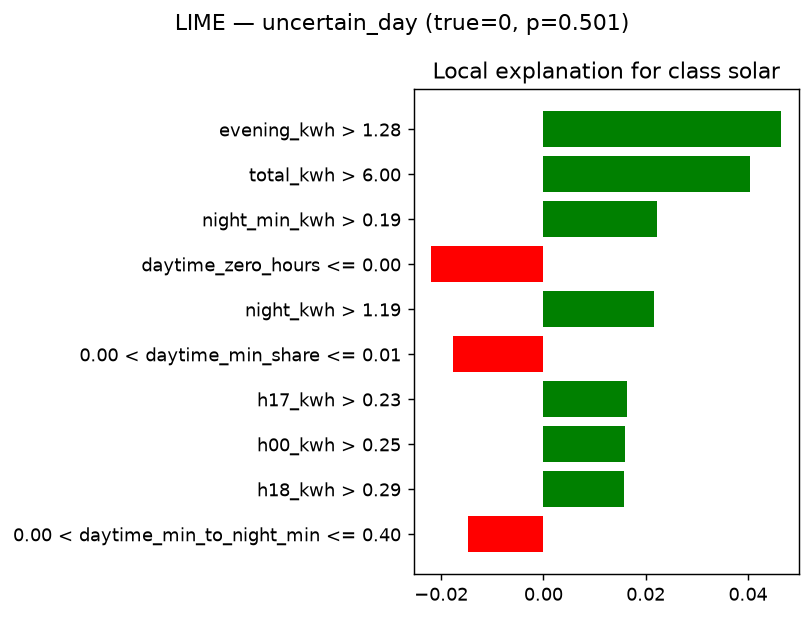

,case,true,p_solar,rule,weight
0,solar_day,1,0.991,daytime_min_share <= 0.00,0.074
1,solar_day,1,0.991,daytime_min_to_night_min <= 0.00,0.048
2,solar_day,1,0.991,evening_kwh > 1.28,0.045
3,solar_day,1,0.991,total_kwh > 6.00,0.037
4,solar_day,1,0.991,h17_kwh > 0.23,0.025
10,non_solar_day,0,0.008,0.01 < daytime_min_share <= 0.02,-0.031
11,non_solar_day,0,0.008,evening_kwh <= 0.33,-0.022
12,non_solar_day,0,0.008,0.40 < daytime_min_to_night_min <= 0.88,-0.022
13,non_solar_day,0,0.008,total_kwh <= 1.83,-0.018
14,non_solar_day,0,0.008,daytime_zero_hours <= 0.00,-0.017


In [13]:
for case in ['solar_day', 'non_solar_day', 'uncertain_day']:
    display(Image(EX + f'lime_{case}.png', width=620))
pd.read_csv(EX + 'lime_explanations.csv').groupby('case').head(5)[['case', 'true', 'p_solar', 'rule', 'weight']].round(3)

LIME fits a simple linear model around one prediction and reports human-readable rules ("daytime_min_share
≤ 0.01 → towards solar"). It agrees with SHAP on the main drivers for the confident cases. For the **uncertain day** (a non-solar
day scored 0.50) the evidence conflicts: high evening and total consumption point towards solar (solar homes tend to be
larger consumers), while the absence of any zero-import daytime hour points away. One day is genuinely ambiguous here,
which is exactly why the household decision averages over many days.

**SHAP vs LIME.** SHAP values are additive and consistent (they sum to the prediction), and tree SHAP is exact;
LIME is model-agnostic and gives intuitive rules but depends on random sampling and the chosen neighbourhood, so its
weights vary slightly between runs. Using both gives a cross-check.

## 8. Why this model is suitable

* **Fits the data**: tabular, engineered shape features with strong but non-linear interactions → tree ensembles.
* **At least as good as any single model, and the best on the test set**: the stacking ensemble combines boosting
  and bagging learners whose errors are partly independent; the margin is small (section 3), so the main benefit is
  robustness rather than a big accuracy jump.
* **Robust**: grouped CV with low spread across folds; hyperparameters and threshold fixed on training households.
* **Explainable**: SHAP and LIME show it uses the physical solar signature, not artefacts.
* **Deployable**: a ~day of 15-minute readings is enough for a day-level score; weeks of data give a reliable
  household flag (section 5).

**Limitations.** One utility area (LECO, Moratuwa), one period; off-grid solar or batteries that never export are
labelled "no solar" by the meter definition; households with very few days of data are less reliable.